# Limitaciones de la aproximación de Poisson

Este notebook genera una figura con dos paneles en horizontal para ilustrar dos situaciones en las que la aproximación de Poisson puede perder precisión:

- número inicial de núcleos pequeño, manteniendo el paso temporal original;
- paso temporal mayor, manteniendo el número inicial de núcleos original.

La figura se guarda como `TAREA2/limitaciones_poisson.png` para poder incluirla directamente en LaTeX.


In [94]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

#########################################################
################ PARÁMETROS GENERALES ###################
#########################################################

Lambda = 1.0                 # año^{-1}
N0 = 1000                    # núcleos iniciales
T_sim = 5.0                  # años
rng = np.random.default_rng(1234568)


plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "axes.grid": False,
    "lines.linewidth": 1.8
})




In [95]:
#########################################################
################ FUNCIÓN DE SIMULACIÓN ##################
#########################################################

def simulacion_poisson(N0, Lambda, T_sim, dt, rng):
    n_pasos = int(round(T_sim / dt))
    tiempos = np.linspace(0, T_sim, n_pasos + 1)

    supervivientes = []
    N = N0

    for _ in tiempos:
        supervivientes.append(N)

        mu = N * (1.0 - np.exp(-Lambda * dt))   # media exacta por paso
        D = rng.poisson(mu)

        # evitar que se desintegren más núcleos de los que quedan
        D = min(D, N)

        N -= D

    return tiempos, np.array(supervivientes)



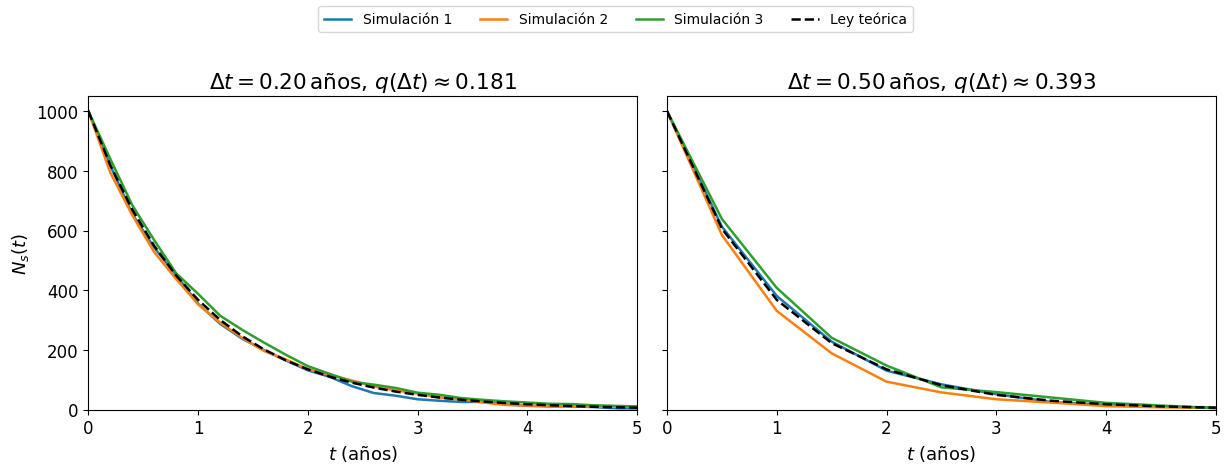

In [96]:
#########################################################
############### COMPARACIÓN DE DOS PASOS ################
#########################################################

dt1 = 0.20
dt2 = 0.50

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)

for ax, dt in zip(axes, [dt1, dt2]):

    # Tres simulaciones independientes
    tiempos, N1 = simulacion_poisson(N0, Lambda, T_sim, dt, rng)
    _, N2 = simulacion_poisson(N0, Lambda, T_sim, dt, rng)
    _, N3 = simulacion_poisson(N0, Lambda, T_sim, dt, rng)

    # Ley teórica
    N_teorica = N0 * np.exp(-Lambda * tiempos)

    # Cada simulación con un color distinto
    ax.plot(tiempos, N1, label="Simulación 1")
    ax.plot(tiempos, N2, label="Simulación 2")
    ax.plot(tiempos, N3, label="Simulación 3")

    # Ley teórica en negro discontinuo
    ax.plot(
        tiempos,
        N_teorica,
        linestyle="--",
        color="black",
        label="Ley teórica"
    )

    q = 1 - np.exp(-Lambda * dt)

    ax.set_title(
        rf"$\Delta t={dt:.2f}\,\mathrm{{años}}$, "
        rf"$q(\Delta t)\approx {q:.3f}$"
    )
    ax.set_xlabel(r"$t$ (años)")
    ax.set_xlim(0, T_sim)
    ax.set_ylim(0, N0 * 1.05)

axes[0].set_ylabel(r"$N_s(t)$")

# Leyenda común
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.savefig("limitaciones_poisson.png", dpi=300, bbox_inches="tight")
plt.show()